# 00_05 Conditional Probability and Bayes' Theorem

**Learning objectives**
- Use **conditional probability**, the **law of total probability** and **Bayes' theorem**.
- Understand the **base-rate fallacy**: why a positive result from an accurate test can still mean a low probability of disease.
- Update beliefs sequentially, using **odds** and **likelihood ratios**.
- Solve a medical-test problem by hand, in code and by simulation (this sets up the confusion matrix of Module 10).

**Prerequisites:** [00_03 Joint and conditional distributions](00_03_joint_conditional.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Conditional probability:** $P(A\mid B)=\dfrac{P(A\cap B)}{P(B)}$.
- **Multiplication rule:** $P(A\cap B)=P(A\mid B)P(B)=P(B\mid A)P(A)$.
- **Partition:** events $B_1,\dots,B_k$ that are disjoint and cover everything (e.g. "sick" and "healthy").
- **Independence:** $P(A\cap B)=P(A)P(B)$.

## 3. Intuition and story

A disease affects **1 %** of people. A test detects it in **90 %** of sick people (sensitivity) and correctly clears **95 %** of healthy people (specificity). You test positive. How worried should you be? Most people say "about 90 %". The right answer is **about 15 %**.

The reason: there are far more healthy people than sick ones. Of 10,000 people, 100 are sick and 90 of them test positive. But 9,900 are healthy and **5 % of them (495 people)** test positive too. So among all 585 positives, only 90 are truly sick: $90/585=15.4\%$. The **base rate** (how common the disease is) matters as much as the test's accuracy.

Bayes' theorem is the formula that **turns around a conditional probability**: from $P(\text{positive}\mid\text{sick})$ (what the test maker measures) to $P(\text{sick}\mid\text{positive})$ (what the patient wants).

## 4. Formal definition

**Law of total probability.** If $B_1,\dots,B_k$ partition the sample space: $P(A)=\sum_iP(A\mid B_i)P(B_i)$.

**Bayes' theorem.**
$$P(B_i\mid A)=\frac{P(A\mid B_i)P(B_i)}{P(A)}=\frac{P(A\mid B_i)P(B_i)}{\sum_jP(A\mid B_j)P(B_j)}.$$
In words: **posterior $\propto$ likelihood $\times$ prior**.

**Odds form.** $\underbrace{\dfrac{P(B\mid A)}{P(B^c\mid A)}}_{\text{posterior odds}}=\underbrace{\dfrac{P(B)}{P(B^c)}}_{\text{prior odds}}\times\underbrace{\dfrac{P(A\mid B)}{P(A\mid B^c)}}_{\text{likelihood ratio}}$.

**Test vocabulary.** Sensitivity $=P(+\mid\text{sick})$ (true positive rate), specificity $=P(-\mid\text{healthy})$ (true negative rate), **PPV** $=P(\text{sick}\mid+)$, **NPV** $=P(\text{healthy}\mid-)$.

## 5. Derivations

**Bayes from the multiplication rule.** $P(A\cap B)=P(A\mid B)P(B)=P(B\mid A)P(A)$; divide by $P(A)$ to get $P(B\mid A)=P(A\mid B)P(B)/P(A)$.

**Total probability.** $A=\bigcup_i(A\cap B_i)$ (disjoint pieces), so $P(A)=\sum_iP(A\cap B_i)=\sum_iP(A\mid B_i)P(B_i)$.

**The medical test.** With $D$ = sick, prevalence $\pi=0.01$, sensitivity $s_e=0.90$, specificity $s_p=0.95$:
$$P(+)=s_e\pi+(1-s_p)(1-\pi)=0.009+0.0495=0.0585,\qquad\text{PPV}=\frac{s_e\pi}{P(+)}=\frac{0.009}{0.0585}=0.154.$$
$$\text{NPV}=\frac{s_p(1-\pi)}{1-P(+)}=\frac{0.9405}{0.9415}=0.9989.$$

**Odds form.** Prior odds $\frac{0.01}{0.99}=\frac1{99}$; likelihood ratio of a positive test $\text{LR}^+=\frac{s_e}{1-s_p}=\frac{0.90}{0.05}=18$; posterior odds $=\frac{18}{99}=0.182$, i.e. probability $\frac{0.182}{1.182}=0.154$ ✓.

**Sequential updating.** If tests are conditionally independent given the disease status, each positive result multiplies the odds by 18. Two positives: odds $\frac{18^2}{99}=3.27$, probability $0.766$. The posterior after one test becomes the prior for the next.

**In plain words.** Start with how common something is, multiply by how much more likely the evidence is if it is true than if it is false, and renormalize.

### In plain words: the derivations in everyday language


- **Bayes' theorem reverses a conditional probability.** We usually know "how likely is this evidence if the hypothesis is true" (the likelihood) but want "how likely is the hypothesis now that we saw the evidence" (the posterior). The theorem converts one into the other using the prior.
- **Prior $\times$ likelihood, then divide by the evidence.** The numerator weighs each hypothesis by how plausible it was *and* how well it explains the data; the denominator, the total probability of the data, just rescales so that the posteriors add to 1.
- **The base rate matters as much as the test.** A very accurate test for a rare condition still produces mostly false alarms, because the huge healthy group generates more false positives than the small sick group generates true ones.
- **Evidence accumulates by multiplying odds.** Each independent result multiplies the odds by its likelihood ratio, so a second positive test moves a doubtful 15 % to a convincing 77 %.
- **Yesterday's posterior is today's prior.** Learning in small steps gives the same answer as learning all at once, which is why Bayesian updating works for streaming data.

## 6. Properties and relationships

- **Base-rate fallacy:** ignoring the prior. PPV depends strongly on prevalence; sensitivity and specificity do not.
- **Confusion matrix** (Module 10): the four counts TP, FN, FP, TN of the natural-frequency table; precision = PPV, recall = sensitivity.
- **Conjugate updating:** for a probability with a Beta prior and Binomial data, Bayes' rule gives a Beta posterior (lesson 02_04).
- **Posterior = prior if the evidence is uninformative** (likelihood ratio 1).
- **Prosecutor's fallacy:** confusing $P(\text{evidence}\mid\text{innocent})$ with $P(\text{innocent}\mid\text{evidence})$.

## 7. 2D visuals

### 7.1 Natural frequencies: 10,000 people
The four groups of the confusion matrix; the highlighted positives show that most of them are false alarms.

{'true positive': 90.0, 'false positive': 495.00000000000045, 'false negative': 10.0, 'true negative': 9405.0}  positives: 585.0000000000005  PPV: 0.1538


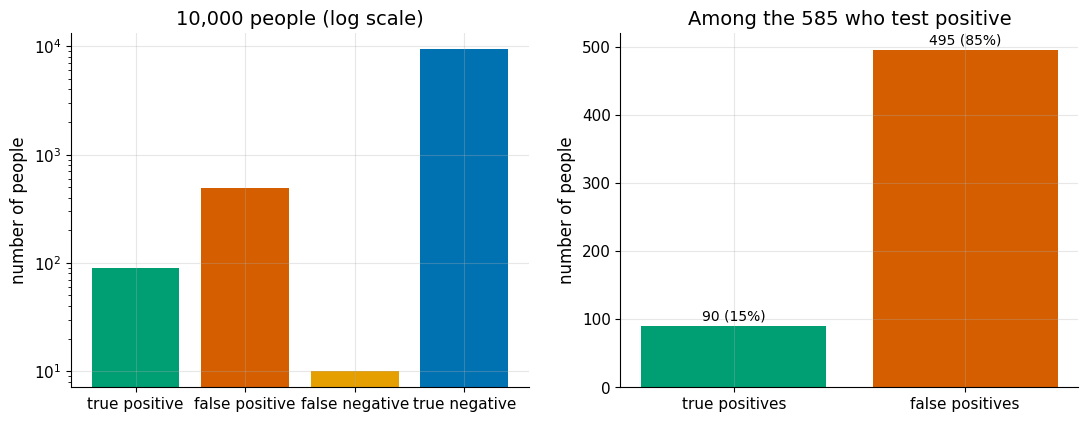

In [2]:
population, prevalence, sensitivity, specificity = 10_000, 0.01, 0.90, 0.95
sick = population * prevalence
true_positive = sick * sensitivity
false_negative = sick - true_positive
healthy = population - sick
false_positive = healthy * (1 - specificity)
true_negative = healthy - false_positive
labels = ["true positive", "false positive", "false negative", "true negative"]
counts = [true_positive, false_positive, false_negative, true_negative]
print(dict(zip(labels, counts)), " positives:", true_positive + false_positive, " PPV:", round(true_positive / (true_positive + false_positive), 4))

fig, (ax_bar, ax_pos) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_bar.bar(labels, counts, color=[COLORS[2], HIGHLIGHT, COLORS[1], COLORS[0]])
ax_bar.set_yscale("log")
ax_bar.set_title("10,000 people (log scale)")
ax_bar.set_ylabel("number of people")
ax_pos.bar(["true positives", "false positives"], [true_positive, false_positive], color=[COLORS[2], HIGHLIGHT])
ax_pos.set_title("Among the 585 who test positive")
ax_pos.set_ylabel("number of people")
for i, value in enumerate([true_positive, false_positive]):
    ax_pos.text(i, value + 8, f"{value:.0f} ({value / (true_positive + false_positive):.0%})", ha="center")
plt.show()

### 7.2 PPV as a function of prevalence
The same test is far more informative when the condition is common. Each curve is a different specificity (sensitivity 90 %).

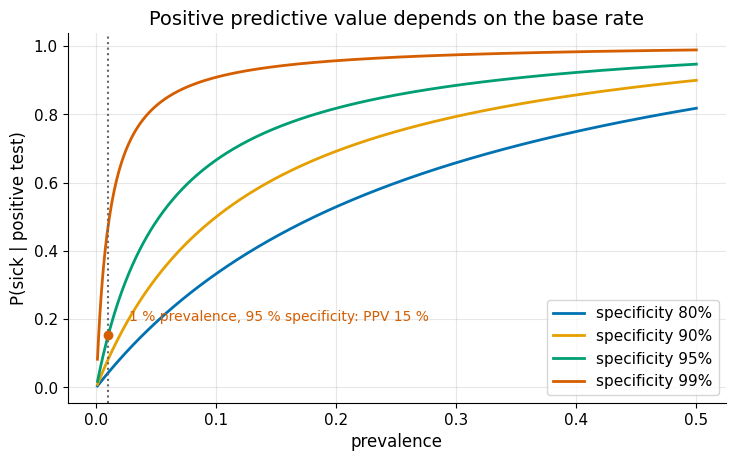

In [3]:
prevalence_axis = np.linspace(0.001, 0.5, 500)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for spec, color in zip([0.80, 0.90, 0.95, 0.99], COLORS):
    ppv = 0.9 * prevalence_axis / (0.9 * prevalence_axis + (1 - spec) * (1 - prevalence_axis))
    ax.plot(prevalence_axis, ppv, color=color, linewidth=2, label=f"specificity {spec:.0%}")
ax.axvline(0.01, color=NEUTRAL, linestyle=":")
ax.plot([0.01], [0.9 * 0.01 / (0.9 * 0.01 + 0.05 * 0.99)], "o", color=HIGHLIGHT)
ax.annotate("1 % prevalence, 95 % specificity: PPV 15 %", (0.01, 0.154), textcoords="offset points", xytext=(15, 10), color=HIGHLIGHT)
ax.set_title("Positive predictive value depends on the base rate")
ax.set_xlabel("prevalence")
ax.set_ylabel("P(sick | positive test)")
ax.legend()
plt.show()

### 7.3 Sequential updating: prior, one positive, two positives
Each positive test multiplies the odds by the likelihood ratio 18.

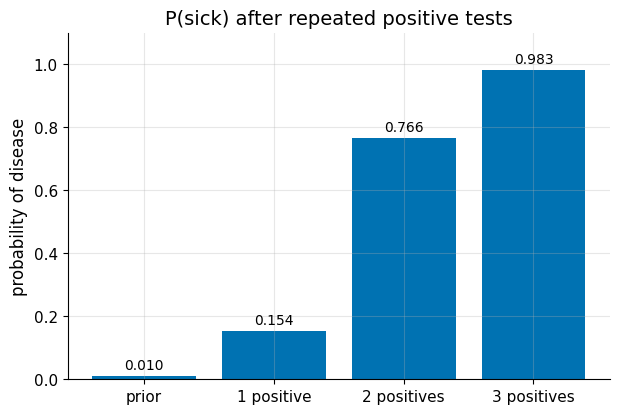

odds check: prior odds 1/99 times 18^n -> [0.01, 0.1538, 0.766, 0.9833]


In [4]:
def update_with_positive(prior, sens=0.90, spec=0.95):
    """Posterior probability of disease after one positive test (Bayes' theorem)."""
    return sens * prior / (sens * prior + (1 - spec) * (1 - prior))

probabilities = [0.01]
for _ in range(3):
    probabilities.append(update_with_positive(probabilities[-1]))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(["prior", "1 positive", "2 positives", "3 positives"], probabilities, color=MAIN)
for i, p in enumerate(probabilities):
    ax.text(i, p + 0.02, f"{p:.3f}", ha="center")
ax.set_ylim(0, 1.1)
ax.set_title("P(sick) after repeated positive tests")
ax.set_ylabel("probability of disease")
plt.show()
print("odds check: prior odds 1/99 times 18^n ->", [round(18**n / 99 / (1 + 18**n / 99), 4) for n in range(4)])

## 8. 3D visuals

### 8.1 Static: PPV over (prevalence, specificity)
The valley is the region where an accurate-looking test gives mostly false alarms: low prevalence, modest specificity.

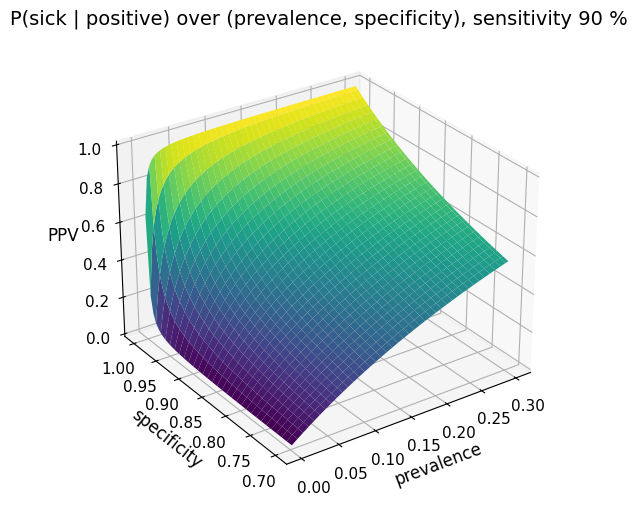

In [5]:
prev_values = np.linspace(0.002, 0.3, 80)
spec_values = np.linspace(0.7, 0.999, 60)
P, S = np.meshgrid(prev_values, spec_values)
PPV = 0.9 * P / (0.9 * P + (1 - S) * (1 - P))
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(P, S, PPV, cmap="viridis", edgecolor="none")
ax.set_title("P(sick | positive) over (prevalence, specificity), sensitivity 90 %")
ax.set_xlabel("prevalence")
ax.set_ylabel("specificity")
ax.set_zlabel("PPV")
ax.view_init(elev=28, azim=-125)
plt.show()

### 8.2 Static: the joint probabilities of (disease, test) as 3D bars

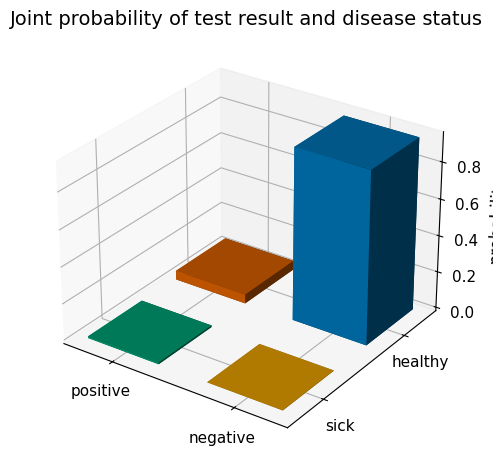

In [6]:
joint = np.array([[prevalence * sensitivity, prevalence * (1 - sensitivity)], [(1 - prevalence) * (1 - specificity), (1 - prevalence) * specificity]])
X2, Y2 = np.meshgrid([0, 1], [0, 1])
fig = plt.figure(figsize=(7.5, 5.5))
ax = fig.add_subplot(projection="3d")
ax.bar3d(X2.ravel() - 0.3, Y2.ravel() - 0.3, np.zeros(4), 0.6, 0.6, joint.ravel(), color=[COLORS[2], COLORS[1], HIGHLIGHT, COLORS[0]])
ax.set_xticks([0, 1]); ax.set_xticklabels(["positive", "negative"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["sick", "healthy"])
ax.set_title("Joint probability of test result and disease status")
ax.set_zlabel("probability")
ax.view_init(elev=28, azim=-55)
plt.show()

### 8.3 Interactive Plotly version of 8.1

In [7]:
fig = go.Figure(go.Surface(x=prev_values, y=spec_values, z=PPV, colorscale="Viridis"))
fig.update_layout(title="PPV over (prevalence, specificity), sensitivity 90 %", width=750, height=550,
                  scene=dict(xaxis_title="prevalence", yaxis_title="specificity", zaxis_title="PPV"))
fig.show()

## 9. Simulation vs theory

### 9.1 Simulating a million people

In [8]:
n_people = 1_000_000
is_sick = rng.uniform(size=n_people) < prevalence
test_positive = np.where(is_sick, rng.uniform(size=n_people) < sensitivity, rng.uniform(size=n_people) < 1 - specificity)
print(f"P(positive): simulated {test_positive.mean():.4f}, theory 0.0585")
print(f"PPV: simulated {is_sick[test_positive].mean():.4f}, theory {update_with_positive(0.01):.4f}")
print(f"NPV: simulated {(~is_sick[~test_positive]).mean():.5f}, theory {0.95 * 0.99 / (1 - 0.0585):.5f}")

P(positive): simulated 0.0587, theory 0.0585
PPV: simulated 0.1533, theory 0.1538
NPV: simulated 0.99886, theory 0.99894


### 9.2 The running estimate of the PPV converges
As more positive results accumulate, the share of sick people among them settles at 15.4 %.

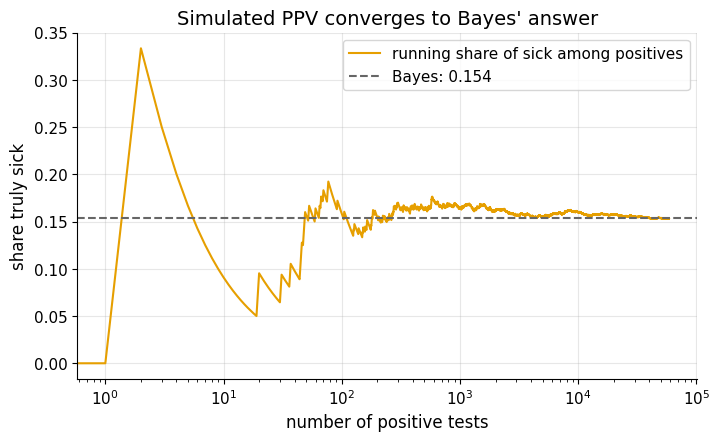

In [9]:
positives_sick = is_sick[test_positive]
running_ppv = np.cumsum(positives_sick) / np.arange(1, len(positives_sick) + 1)
fig, ax = plt.subplots()
ax.plot(running_ppv, color=SIM, label="running share of sick among positives")
ax.axhline(update_with_positive(0.01), color=NEUTRAL, linestyle="--", label="Bayes: 0.154")
ax.set_xscale("log")
ax.set_title("Simulated PPV converges to Bayes' answer")
ax.set_xlabel("number of positive tests")
ax.set_ylabel("share truly sick")
ax.legend()
plt.show()

## 10. `scipy` tools

Bayes' theorem needs no special functions, but `scipy.stats` helps with repeated tests (Binomial) and with uncertainty about the prevalence itself (Beta).

In [10]:
tests_positive = stats.binom(n=2, p=0.9)                         # two tests on a sick person: number of positives
print("P(both tests positive | sick) =", round(tests_positive.pmf(2), 4), " | healthy: ", round(stats.binom(2, 0.05).pmf(2), 4))
prior_prevalence = stats.beta(a=2, b=198)                          # uncertain prevalence, mean 1 %
print("prevalence prior: mean", round(prior_prevalence.mean(), 4), " 95 % interval", np.round(prior_prevalence.interval(0.95), 4))
survey = stats.beta(a=2 + 12, b=198 + 988)                         # update after 12 sick out of 1,000 sampled
print("posterior mean after 12 sick in 1000:", round(survey.mean(), 4))

P(both tests positive | sick) = 0.81  | healthy:  0.0025
prevalence prior: mean 0.01  95 % interval [0.0012 0.0277]
posterior mean after 12 sick in 1000: 0.0117


## 11. Real-world worked example: a medical test

**Scenario (illustrative numbers).** Prevalence **1 %**, sensitivity **90 %**, specificity **95 %**.

**Questions**
1. What is the **overall probability of a positive test**?
2. Given a **positive test**, what is the probability of disease (PPV)? Given a **negative** test, the probability of being healthy (NPV)?
3. After **two independent positive tests**, what is the probability of disease?
4. If the prevalence were **10 %** (a high-risk group), what is the PPV?

### 11.1 By hand
**Q1.** $P(+)=0.90\times0.01+0.05\times0.99=0.009+0.0495=0.0585$.

**Q2.** PPV $=\frac{0.009}{0.0585}=0.1538$; NPV $=\frac{0.95\times0.99}{1-0.0585}=\frac{0.9405}{0.9415}=0.9989$.

**Q3.** Odds after two positives $=\frac1{99}\times18^2=3.273$, probability $=\frac{3.273}{4.273}=0.766$.

**Q4.** $P(+)=0.9\times0.1+0.05\times0.9=0.135$; PPV $=\frac{0.09}{0.135}=0.667$.

In [11]:
def bayes_ppv(prevalence, sensitivity, specificity):
    # Bayes' theorem: P(sick | +) = P(+ | sick) P(sick) / P(+), with P(+) from the law of total probability
    p_positive = sensitivity * prevalence + (1 - specificity) * (1 - prevalence)
    return sensitivity * prevalence / p_positive

p_positive_hand = 0.90 * 0.01 + 0.05 * 0.99
ppv_hand = bayes_ppv(0.01, 0.90, 0.95)
npv_hand = 0.95 * 0.99 / (1 - p_positive_hand)
odds_two = (0.01 / 0.99) * 18**2
two_positive_hand = odds_two / (1 + odds_two)
ppv_10_hand = bayes_ppv(0.10, 0.90, 0.95)
print(f"P(+) = {p_positive_hand:.4f}; PPV = {ppv_hand:.4f}; NPV = {npv_hand:.4f}; after two positives = {two_positive_hand:.4f}; PPV at 10 % prevalence = {ppv_10_hand:.4f}")

P(+) = 0.0585; PPV = 0.1538; NPV = 0.9989; after two positives = 0.7660; PPV at 10 % prevalence = 0.6667


### 11.2 In code, and the asserts
We rebuild the answers from the full joint table (the four counts) and from sequential Bayes updating, and check all against the hand results.

In [12]:
joint_table = pd.DataFrame({"positive": [0.01 * 0.90, 0.99 * 0.05], "negative": [0.01 * 0.10, 0.99 * 0.95]}, index=["sick", "healthy"])
ppv_code = joint_table.loc["sick", "positive"] / joint_table["positive"].sum()
npv_code = joint_table.loc["healthy", "negative"] / joint_table["negative"].sum()
posterior_two_code = update_with_positive(update_with_positive(0.01))
assert np.isclose(joint_table["positive"].sum(), p_positive_hand)
assert np.isclose(ppv_code, ppv_hand)
assert np.isclose(npv_code, npv_hand)
assert np.isclose(posterior_two_code, two_positive_hand)
assert np.isclose(update_with_positive(0.10), ppv_10_hand)
print(joint_table.round(5)); print(f"PPV {ppv_code:.4f}, NPV {npv_code:.5f}, two positives {posterior_two_code:.4f}")

         positive  negative
sick       0.0090    0.0010
healthy    0.0495    0.9405
PPV 0.1538, NPV 0.99894, two positives 0.7660


### 11.3 Verify by simulation
Two tests per person are simulated with independent test errors.

In [13]:
second_test = np.where(is_sick, rng.uniform(size=n_people) < sensitivity, rng.uniform(size=n_people) < 1 - specificity)
both_positive = test_positive & second_test
print(f"after two positives: simulated {is_sick[both_positive].mean():.4f}, Bayes {two_positive_hand:.4f}")
high_risk = rng.uniform(size=n_people) < 0.10
high_risk_positive = np.where(high_risk, rng.uniform(size=n_people) < 0.9, rng.uniform(size=n_people) < 0.05)
print(f"10 % prevalence: simulated PPV {high_risk[high_risk_positive].mean():.4f}, Bayes {ppv_10_hand:.4f}")
assert abs(is_sick[both_positive].mean() - two_positive_hand) < 0.02
assert abs(high_risk[high_risk_positive].mean() - ppv_10_hand) < 0.005

after two positives: simulated 0.7666, Bayes 0.7660
10 % prevalence: simulated PPV 0.6646, Bayes 0.6667


### 11.4 Plots

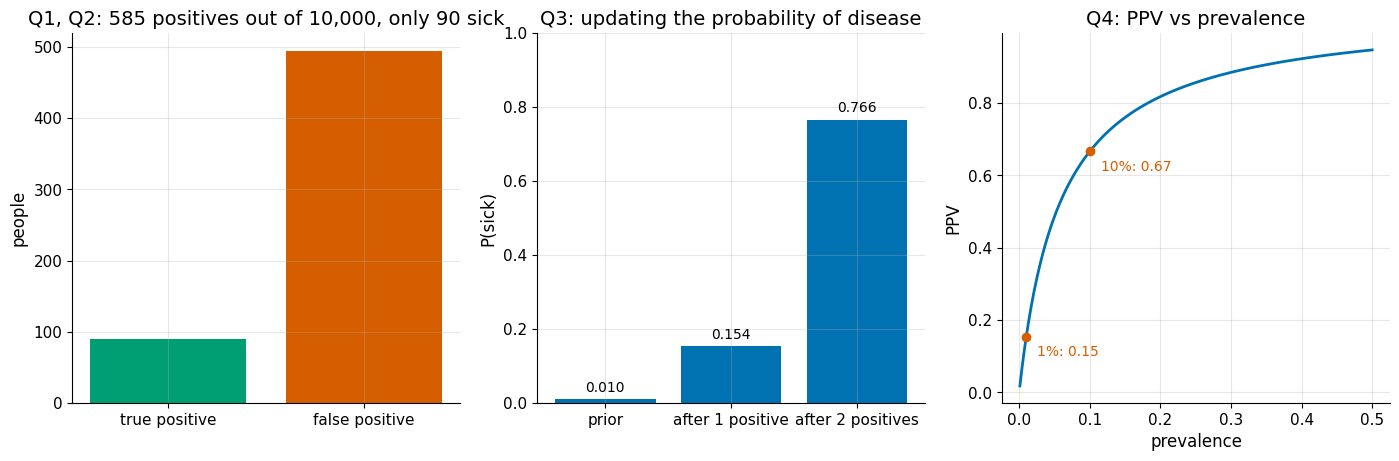

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].bar(["true positive", "false positive"], [90, 495], color=[COLORS[2], HIGHLIGHT])
axes[0].set_title("Q1, Q2: 585 positives out of 10,000, only 90 sick")
axes[0].set_ylabel("people")
axes[1].bar(["prior", "after 1 positive", "after 2 positives"], [0.01, ppv_hand, two_positive_hand], color=MAIN)
for i, p in enumerate([0.01, ppv_hand, two_positive_hand]):
    axes[1].text(i, p + 0.02, f"{p:.3f}", ha="center")
axes[1].set_ylim(0, 1)
axes[1].set_title("Q3: updating the probability of disease")
axes[1].set_ylabel("P(sick)")
axes[2].plot(prevalence_axis, 0.9 * prevalence_axis / (0.9 * prevalence_axis + 0.05 * (1 - prevalence_axis)), color=MAIN, linewidth=2)
for prev, value in [(0.01, ppv_hand), (0.10, ppv_10_hand)]:
    axes[2].plot([prev], [value], "o", color=HIGHLIGHT)
    axes[2].annotate(f"{prev:.0%}: {value:.2f}", (prev, value), textcoords="offset points", xytext=(8, -14), color=HIGHLIGHT)
axes[2].set_title("Q4: PPV vs prevalence")
axes[2].set_xlabel("prevalence")
axes[2].set_ylabel("PPV")
plt.show()

### 11.5 Interpretation and decision
- Only **5.9 %** of people test positive overall, but **84.6 % of those positives are healthy**: PPV is just **15 %**. A negative test is very reassuring (NPV 99.9 %).
- A **second independent positive** raises the probability to **77 %**: confirmatory testing is the right response to a first positive in a low-prevalence setting.
- In a high-risk group (10 % prevalence) the same test has PPV **67 %**: screen where the base rate is high, and always follow up positives from mass screening.
- **Decision:** explain results with natural frequencies ("of 585 positives, about 90 are truly sick") and order a confirmatory test instead of treating on one positive.

### 11.6 Extra example: a spam filter
30 % of email is spam. The word "free" appears in **60 % of spam** and **5 % of legitimate mail**. What is $P(\text{spam}\mid\text{"free"})$?

In [15]:
p_spam_free_hand = (0.60 * 0.30) / (0.60 * 0.30 + 0.05 * 0.70)
assert np.isclose(p_spam_free_hand, bayes_ppv(0.30, 0.60, 1 - 0.05))
mails = rng.uniform(size=1_000_000) < 0.30
contains_free = np.where(mails, rng.uniform(size=1_000_000) < 0.60, rng.uniform(size=1_000_000) < 0.05)
print(f"P(spam | 'free') = {p_spam_free_hand:.4f}; simulated {mails[contains_free].mean():.4f}")

P(spam | 'free') = 0.8372; simulated 0.8374


**Interpretation.** Seeing "free" moves the spam probability from 30 % to **84 %**: the likelihood ratio is 12. A real filter (Naive Bayes, Module 09) multiplies the likelihood ratios of *all* words in the email.

---
### Example 2: which coin is it? (updating with several observations)

**Scenario (illustrative).** A box contains two coins and you pick one at random: a **fair** coin ($p=0.5$) and a **biased** coin that lands heads with probability $p=0.7$. You toss the chosen coin **10 times** and see **7 heads**.

**Questions**
1. What is the probability that you hold the biased coin, given 7 heads in 10 tosses?
2. How do the posterior and the likelihood ratio change if you see **70 heads in 100 tosses**?
3. After the 10 tosses, what is the probability that the **next toss** is a head?

### 11.6 By hand

**Q1.** Likelihoods: $P(7\mid\text{fair})=\binom{10}7(0.5)^{10}=120/1024=0.1172$; $P(7\mid\text{biased})=\binom{10}7(0.7)^7(0.3)^3=120\times0.08235\times0.027=0.2668$. With prior 1/2 each, $P(\text{biased}\mid7)=\dfrac{0.2668}{0.2668+0.1172}=\mathbf{0.695}$.

**Q2.** For 70 heads in 100: the likelihood ratio is $\dfrac{0.7^{70}0.3^{30}}{0.5^{100}}=e^{70\ln1.4+30\ln0.6}=e^{70(0.3365)+30(-0.5108)}=e^{8.23}\approx3{,}700$, so $P(\text{biased})\approx1-1/3700=\mathbf{0.9997}$.

**Q3.** By total probability $P(\text{head})=0.695(0.7)+0.305(0.5)=\mathbf{0.639}$.

likelihoods 0.1172 (fair), 0.2668 (biased) | P(biased | 7 of 10) = 0.6948 | LR for 70 of 100 = 3,745, posterior 0.99973 | P(next is head) = 0.6390
simulation: among runs with exactly 7 heads, share that used the biased coin = 0.6938 (exact 0.6948)


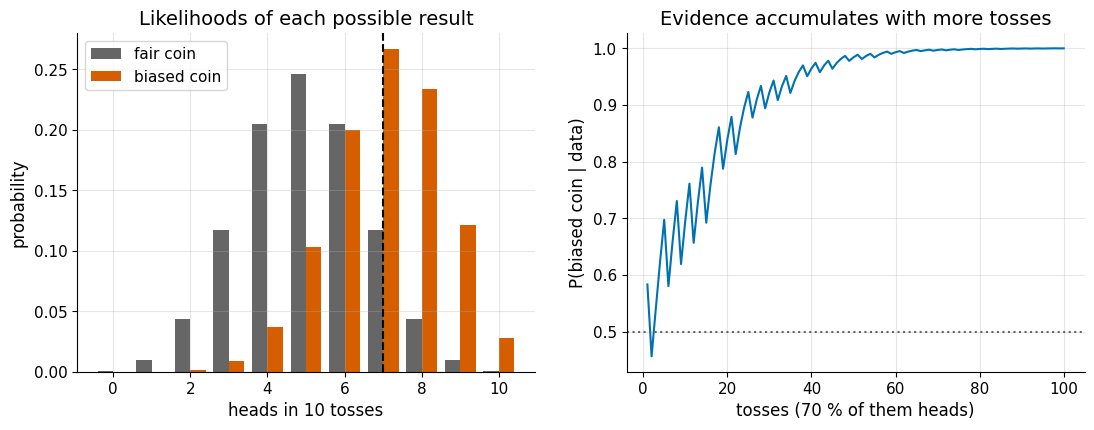

In [16]:
lik_f, lik_b = stats.binom(10, 0.5).pmf(7), stats.binom(10, 0.7).pmf(7)
post_b = lik_b / (lik_f + lik_b)
lr100 = stats.binom(100, 0.7).pmf(70) / stats.binom(100, 0.5).pmf(70); post_b100 = lr100 / (1 + lr100)
p_next = post_b * 0.7 + (1 - post_b) * 0.5
print(f"likelihoods {lik_f:.4f} (fair), {lik_b:.4f} (biased) | P(biased | 7 of 10) = {post_b:.4f} | LR for 70 of 100 = {lr100:,.0f}, posterior {post_b100:.5f} | P(next is head) = {p_next:.4f}")
assert abs(post_b - 0.6948) < 5e-4 and post_b100 > 0.999 and abs(p_next - 0.6390) < 5e-4
sim_g = np.random.default_rng(14); n_s = 600_000
biased = sim_g.random(n_s) < 0.5; heads = sim_g.binomial(10, np.where(biased, 0.7, 0.5))
print(f"simulation: among runs with exactly 7 heads, share that used the biased coin = {biased[heads == 7].mean():.4f} (exact {post_b:.4f})")
assert abs(biased[heads == 7].mean() - post_b) < 0.006
ks_c = np.arange(0, 11); fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].bar(ks_c - 0.2, stats.binom(10, 0.5).pmf(ks_c), 0.4, color=NEUTRAL, label="fair coin"); axes[0].bar(ks_c + 0.2, stats.binom(10, 0.7).pmf(ks_c), 0.4, color=HIGHLIGHT, label="biased coin")
axes[0].axvline(7, color="black", linestyle="--"); axes[0].set_xlabel("heads in 10 tosses"); axes[0].set_ylabel("probability"); axes[0].set_title("Likelihoods of each possible result"); axes[0].legend()
nn_c = np.arange(0, 101); post_curve = [(lambda lr: lr / (1 + lr))(stats.binom(n_, 0.7).pmf(round(0.7 * n_)) / stats.binom(n_, 0.5).pmf(round(0.7 * n_))) for n_ in nn_c[1:]]
axes[1].plot(nn_c[1:], post_curve, color=MAIN); axes[1].axhline(0.5, color=NEUTRAL, linestyle=":"); axes[1].set_xlabel("tosses (70 % of them heads)"); axes[1].set_ylabel("P(biased coin | data)"); axes[1].set_title("Evidence accumulates with more tosses")
plt.show()

### 11.7 Interpretation and decision (Example 2)

- Seven heads in ten tosses is **more than twice as likely** under the biased coin (0.267 against 0.117), so the posterior moves from the prior 50 % to **69.5 %**: suggestive, not conclusive. The simulation of 600,000 runs agrees (69.5 %).
- The same *proportion* of heads over **100 tosses** gives a likelihood ratio near 3,700 and a posterior of **99.97 %**: more data means more certainty even though the proportion of heads is the same. Certainty depends on the amount of evidence, not only on its direction.
- The chance that the next toss is a head is **63.9 %**, a weighted average of 0.7 and 0.5, closer to 0.7 because the biased coin is now the better bet.
- **Decision.** Do not accuse the coin (or the supplier) on ten tosses; collect around fifty before deciding, and keep the prior in mind: if biased coins are rare, the posterior is smaller than 70 %.

---
### Example 3: incident triage with two alerts (naive Bayes)

**Scenario (illustrative).** A web service has outages caused by the **database** (20 % of incidents), the **network** (50 %) or the **application** (30 %). Two alerts may fire: *high latency* appears in 90 %, 60 % and 30 % of database, network and application incidents respectively; *timeouts* appear in 70 %, 80 % and 20 %. Assume the alerts are independent given the cause (the naive Bayes assumption).

**Questions**
1. Both alerts fire. What is the probability of each cause?
2. Only *high latency* fires (no timeouts). What now?
3. Which team should be paged first in each case?

### 11.8 By hand

**Q1.** Joint weights for "both alerts": database $0.20\times0.9\times0.7=0.126$; network $0.50\times0.6\times0.8=0.240$; application $0.30\times0.3\times0.2=0.018$. Total $0.384$, so the posteriors are $0.328,\ 0.625,\ 0.047$.

**Q2.** Latency but no timeouts: database $0.20\times0.9\times0.3=0.054$; network $0.50\times0.6\times0.2=0.060$; application $0.30\times0.3\times0.8=0.072$; total $0.186$, posteriors $0.290,\ 0.323,\ 0.387$.

**Q3.** Case 1: the **network** team (62.5 %). Case 2: the **application** team is the most likely (38.7 %), but the three causes are nearly equally plausible.

both alerts      : {'database': np.float64(0.328), 'network': np.float64(0.625), 'application': np.float64(0.047)}
latency only     : {'database': np.float64(0.29), 'network': np.float64(0.323), 'application': np.float64(0.387)}
no alerts at all : {'database': np.float64(0.028), 'network': np.float64(0.187), 'application': np.float64(0.785)}
simulation, both alerts: [0.328 0.626 0.047]


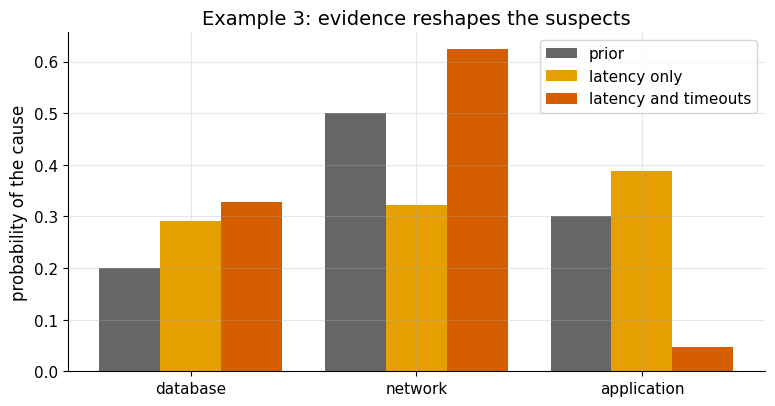

In [17]:
causes = ["database", "network", "application"]; prior_t = np.array([0.20, 0.50, 0.30])
p_latency = np.array([0.9, 0.6, 0.3]); p_timeout = np.array([0.7, 0.8, 0.2])
def posterior_t(lat, tmo):
    like = np.where(lat, p_latency, 1 - p_latency) * np.where(tmo, p_timeout, 1 - p_timeout)
    w = prior_t * like; return w / w.sum()
both, only_lat = posterior_t(True, True), posterior_t(True, False)
print("both alerts      :", dict(zip(causes, both.round(3))))
print("latency only     :", dict(zip(causes, only_lat.round(3))))
print("no alerts at all :", dict(zip(causes, posterior_t(False, False).round(3))))
assert np.allclose(both, np.array([0.126, 0.240, 0.018]) / 0.384) and np.isclose(only_lat.sum(), 1) and both.argmax() == 1 and only_lat.argmax() == 2
g_t = np.random.default_rng(23); n_t = 800_000
cause_t = g_t.choice(3, n_t, p=prior_t); lat_t = g_t.random(n_t) < p_latency[cause_t]; tmo_t = g_t.random(n_t) < p_timeout[cause_t]
sel = lat_t & tmo_t; sim_both = np.bincount(cause_t[sel], minlength=3) / sel.sum()
print("simulation, both alerts:", sim_both.round(3))
assert np.allclose(sim_both, both, atol=0.006)
fig, ax = plt.subplots(figsize=(9, 4.4)); xx_t = np.arange(3)
ax.bar(xx_t - 0.27, prior_t, 0.27, color=NEUTRAL, label="prior"); ax.bar(xx_t, only_lat, 0.27, color=SIM, label="latency only"); ax.bar(xx_t + 0.27, both, 0.27, color=HIGHLIGHT, label="latency and timeouts")
ax.set_xticks(xx_t); ax.set_xticklabels(causes); ax.set_ylabel("probability of the cause"); ax.set_title("Example 3: evidence reshapes the suspects"); ax.legend()
plt.show()

### 11.9 Interpretation and decision (Example 3)

- With **both alerts** the network is the prime suspect (**62.5 %**, up from a prior of 50 %); the database rises from 20 % to 32.8 % and the application drops to 4.7 %. The simulation of 800,000 incidents gives the same posteriors.
- With **latency but no timeouts** the evidence points weakly to the application (**38.7 %**) but the three causes remain close (29 %, 32 %, 39 %): absent timeouts are informative too, because they are rarer for the network (20 %) than for the application (80 %).
- **Decision.** Page the network team first when both alerts fire; when only latency fires, start a parallel check of the application and the network rather than trusting a single guess. The same calculation scales to many alerts (naive Bayes), but remember that alerts caused by one root problem are *not* independent in reality.

## 12. Where it is used

### Statistics
- **Bayesian inference** (posterior = prior x likelihood), hypothesis testing and the false-discovery rate, diagnostic-test evaluation (sensitivity, specificity, PPV).

### Data science
- **Fraud and anomaly screening** (base rates are tiny), A/B-test decisions, spam and churn classifiers, interpreting alert precision.

### ML and AI
- **Naive Bayes classifiers**, Bayesian networks, probabilistic generative models; the **confusion matrix, precision and recall** (Module 10); Bayesian updating in bandits (Module 07).

## 13. Common pitfalls and misconceptions

- **Base-rate neglect:** a 95 %-accurate test does not mean a 95 % chance of disease.
- **P(A | B) is not P(B | A):** the prosecutor's fallacy.
- **Sensitivity and specificity do not depend on prevalence;** PPV and NPV do.
- **Independent tests are an assumption:** repeating the *same* flawed test is not independent evidence; errors may be correlated.
- **The prior matters:** with little data the posterior is dominated by the prior; state it explicitly.
- **Accuracy is misleading for rare conditions:** a classifier that always says "healthy" is 99 % accurate here.

## 14. Exercises

1. A factory has two machines: A makes 60 % of the items with 2 % defects; B makes 40 % with 5 % defects. A random item is defective. What is the probability it came from B?
2. A test has sensitivity 99 % and specificity 99 %. At a prevalence of 0.1 %, what is the PPV?
3. In the medical example, what specificity would be needed for a PPV of 50 % at 1 % prevalence (sensitivity 90 %)?
4. Using odds, find the probability of disease after **three** positive tests starting from 1 %.
5. (Harder) A test is positive for 40 % of the people who have the disease and 10 % of those who do not. Show that after one positive the odds of disease are exactly 4 times the prior odds, and find the posterior probability if the prior is 10 %.

6. A drug test has prevalence 2 %, sensitivity 95 % and specificity 90 %. Find the probability that a person who tests positive is a user, and the probability that a negative result is correct.
7. Urn A holds 3 red and 2 blue balls; urn B holds 1 red and 4 blue. An urn is chosen at random and one ball drawn: it is red. Find the probability that it came from urn A. Then a second ball is drawn from the same urn (with replacement) and is also red: update again.
8. The prior odds of a fault are 1 to 99 and a diagnostic has likelihood ratio 18 for a positive result. Find the posterior probability after one, two and three independent positive results.

Solutions are at the end.

## 15. Summary table

| Quantity | Formula |
|---|---|
| Total probability | P(A) = sum P(A given Bi) P(Bi) |
| Bayes | P(Bi given A) = P(A given Bi) P(Bi) / P(A) |
| Odds form | posterior odds = prior odds x likelihood ratio |
| Sensitivity, specificity | P(+ given sick), P(- given healthy) |
| PPV, NPV | P(sick given +), P(healthy given -) |
| LR+ | sensitivity / (1 - specificity) |

## Solutions

In [18]:
print("1: P(B | defective) =", round(0.4 * 0.05 / (0.6 * 0.02 + 0.4 * 0.05), 4))
print("2: PPV =", round(bayes_ppv(0.001, 0.99, 0.99), 4))
specificity_needed = 1 - (0.9 * 0.01 * (1 - 0.5) / 0.5) / 0.99
print("3: specificity needed =", round(specificity_needed, 5), " check PPV:", round(bayes_ppv(0.01, 0.9, specificity_needed), 4))
print("4: after three positives:", round(18**3 / 99 / (1 + 18**3 / 99), 4))
lr = 0.4 / 0.10
prior_odds = 0.10 / 0.90
print("5: LR+ =", lr, " posterior =", round(prior_odds * lr / (1 + prior_odds * lr), 4))

1: P(B | defective) = 0.625
2: PPV = 0.0902
3: specificity needed = 0.99091  check PPV: 0.5
4: after three positives: 0.9833
5: LR+ = 4.0  posterior = 0.3077


**1.** $P(B\mid D)=\dfrac{0.4\times0.05}{0.6\times0.02+0.4\times0.05}=\dfrac{0.020}{0.032}=0.625$.

**2.** $P(+)=0.99\times0.001+0.01\times0.999=0.01098$; PPV $=\frac{0.00099}{0.01098}=0.090$: only 9 % despite a "99 % accurate" test.

**3.** PPV $=0.5$ needs $\text{FP}=\text{TP}$: $(1-s_p)\times0.99=0.009$, so $s_p=1-0.00909=0.9909$ (about 99.1 %).

**4.** Odds $=\frac{18^3}{99}=58.9$, probability $=0.983$.

**5.** $\text{LR}^+=0.4/0.10=4$: posterior odds are 4 times the prior odds. With prior $0.10$ (odds $1/9$): posterior odds $4/9$, probability $4/13=0.308$. (One positive test multiplies the odds by the likelihood ratio, here 4, and no more.)

### Solutions to the additional exercises

Each answer is computed below and checked.

In [19]:
pr6, se6, sp6 = 0.02, 0.95, 0.90
ppv6 = se6 * pr6 / (se6 * pr6 + (1 - sp6) * (1 - pr6)); npv6 = sp6 * (1 - pr6) / (sp6 * (1 - pr6) + (1 - se6) * pr6)
print(f"6: PPV = {ppv6:.4f}, NPV = {npv6:.4f}")
w7 = np.array([0.5 * 3 / 5, 0.5 * 1 / 5]); a7 = w7 / w7.sum(); w7b = a7 * np.array([3 / 5, 1 / 5]); a7b = w7b / w7b.sum()
print(f"7: P(urn A | red) = {a7[0]:.3f} | after a second red = {a7b[0]:.3f}")
odds8 = 1 / 99 * 18 ** np.arange(1, 4)
print(f"8: posterior probability after 1, 2, 3 positive results: {(odds8 / (1 + odds8)).round(4)}")
assert abs(ppv6 - 0.1624) < 5e-4 and np.isclose(a7[0], 0.75) and np.isclose(a7b[0], 0.9)

6: PPV = 0.1624, NPV = 0.9989
7: P(urn A | red) = 0.750 | after a second red = 0.900
8: posterior probability after 1, 2, 3 positive results: [0.1538 0.766  0.9833]
